In [17]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer, WordNetLemmatizer
import warnings
warnings.filterwarnings("ignore")
from sklearn.linear_model import LogisticRegression

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [19]:
train = pd.read_csv('../data/training.csv', encoding = "ISO-8859-1")
test = pd.read_csv('../data/test-Ans.csv', encoding = "ISO-8859-1")
train.head(5)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\r\nWhy the edits made under my use...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,\r\nMore\r\nI can't make any real suggestions ...,0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


## 数据探索

In [20]:
df_toxic = train.drop(['id', 'comment_text'], axis =1)
df_toxic

,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0,0,0,0,0,0
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0
...,...,...,...,...,...,...
127652,0,0,0,0,0,0
127653,0,0,0,0,0,0
127654,0,0,0,0,0,0
127655,0,0,0,0,0,0


In [21]:
categories = list(df_toxic.columns.values)

counts = []

for i in categories:
    counts.append((i, df_toxic[i].sum()))
    
counts

[('toxic', 12182),
 ('severe_toxic', 1275),
 ('obscene', 6744),
 ('threat', 389),
 ('insult', 6268),
 ('identity_hate', 1121)]

In [22]:
df_state = pd.DataFrame(counts, columns=['category', 'number_of_comments'])
df_state

,category,number_of_comments
0,toxic,12182
1,severe_toxic,1275
2,obscene,6744
3,threat,389
4,insult,6268
5,identity_hate,1121


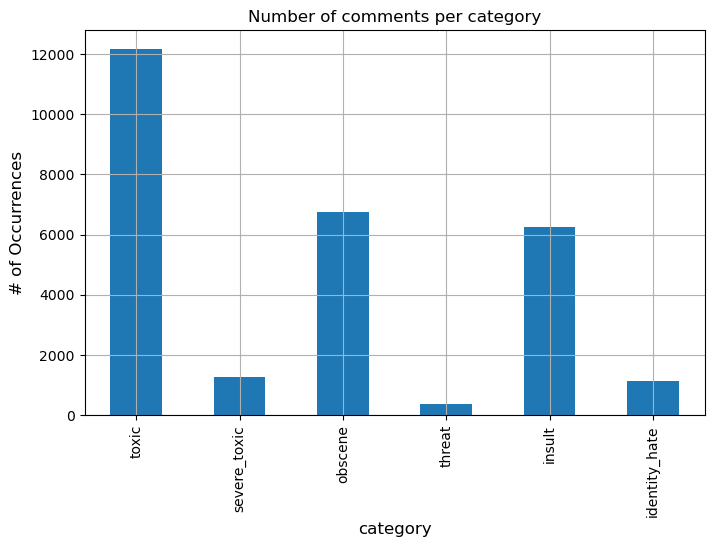

In [23]:
df_state.plot(x='category', y='number_of_comments', kind='bar', legend=False, grid=True, figsize=(8, 5))
plt.title("Number of comments per category")
plt.ylabel('# of Occurrences', fontsize=12)
plt.xlabel('category', fontsize=12)
plt.show()

## 多少评论有多个标签

In [24]:
rowsums = df_toxic.sum(axis=1)
x = rowsums.value_counts()
x

0    114733
1      5046
3      3344
2      2800
4      1395
5       313
6        26
dtype: int64

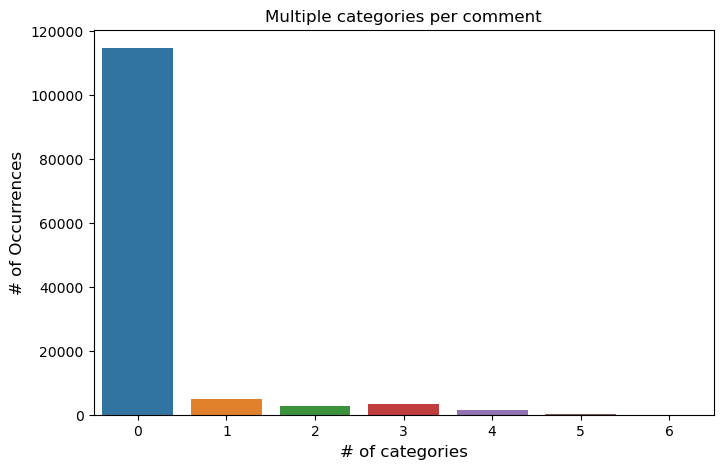

In [25]:
#rowsums = train.iloc[:,2:].sum(axis=1)
rowsums = df_toxic.sum(axis=1)
x = rowsums.value_counts()

#plot
plt.figure(figsize=(8,5))
ax = sns.barplot(x=x.index, y=x.values)
plt.title("Multiple categories per comment")
plt.ylabel('# of Occurrences', fontsize=12)
plt.xlabel('# of categories', fontsize=12)
plt.show()

## 评论文本中词汇数量的分布

In [26]:
train.comment_text.str.len()

0         265
1         112
2         233
3         618
4          67
         ... 
127652    653
127653    101
127654     83
127655    116
127656    181
Name: comment_text, Length: 127657, dtype: int64

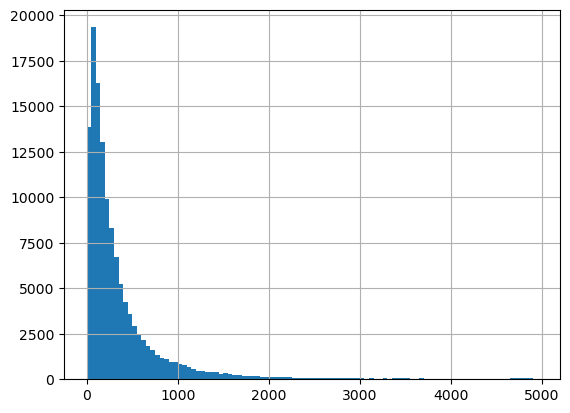

In [27]:
lens = train.comment_text.str.len()
lens.hist(bins = np.arange(0,5000,50))
plt.show()

## 清洗文本

In [28]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"what's", "what is ", text)
    text = re.sub(r"\'s", " is ", text)
    text = re.sub(r"\'ve", " have ", text)
    text = re.sub(r"can't", "can not ", text)
    text = re.sub(r"n't", " not ", text)
    text = re.sub(r"i'm", "i am ", text)
    text = re.sub(r"\'re", " are ", text)
    text = re.sub(r"\'d", " would ", text)
    text = re.sub(r"\'ll", " will ", text)
    text = re.sub(r"\'scuse", " excuse ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return(text)

In [29]:
train['comment_text'] = train['comment_text'].map(lambda com : clean_text(com)) ###用于测试集
test['comment_text'] = test['comment_text'].map(lambda com : clean_text(com)) ###用于测试集

## 去停用词

In [30]:
import pandas as pd
stopwords=pd.read_csv('stopwords.csv')
stopwords=stopwords['停用词'].tolist()
stopwords[:5]

["'d", "'ll", "'m", "'re", "'s"]

In [31]:
#实现功能：分词，去停用词
def f(x):
    current_segment = x.split(' ') #分词
    current_segment=[segment for segment in current_segment if segment not in stopwords]
    segments=" ".join(current_segment) #用空格分开的字符串
    return segments

In [32]:
train['comment_text'] = train['comment_text'].apply(f)
train['comment_text'][:5]

0    explanation edits username hardcore metallica ...
1    aww matches background colour seemingly stuck ...
2    hey edit war guy constantly removing relevant ...
3    real suggestions improvement wondered statisti...
4                             sir hero chance remember
Name: comment_text, dtype: object

In [33]:
test['comment_text'] = test['comment_text'].apply(f)
test['comment_text'][:5]

0                                            bbq phone
1    juelz santanas age 2002 juelz santana 18 febru...
2      redirect talk voydan pop georgiev chernodrinski
3             mitsurugi sense argue hindi ryo sakazaki
4    signpost 24 september 2012 read signpost singl...
Name: comment_text, dtype: object

In [34]:
train_text = train['comment_text']
test_text = test['comment_text']
all_text = pd.concat([train_text, test_text])

## 特征提取

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union

word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    ngram_range=(1, 2),
    min_df=3, 
    #stop_words='english',
    max_features=30000)

char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    ngram_range=(1, 4),
    min_df=3, 
    #stop_words='english',
    max_features=30000)
vectorizer = make_union(word_vectorizer, char_vectorizer, n_jobs=2)

In [36]:
vectorizer.fit(all_text)
train_features = vectorizer.transform(train_text)
test_features = vectorizer.transform(test_text)

In [37]:
train_features.shape, test_features.shape

((127657, 60000), (31914, 60000))

## 训练集和测试集划分

In [38]:
from sklearn.model_selection import train_test_split

class_names = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
x_train, x_test, y_train, y_test = train_test_split(train_features, train[class_names], random_state=2022)

## 逻辑回归

In [39]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score

SMO = SMOTE(random_state=3)

scores_train = []
scores_test = []
scores = []

submission = pd.DataFrame.from_dict({'id': test['id']})

for class_name in class_names:
    print(class_name)
    #train_target = y_train[class_name]
    over_samples_x, over_samples_y = SMO.fit_resample(x_train, y_train[class_name])##过采样
    
    #cv_score = np.mean(cross_val_score(classifier, over_samples_x, over_samples_y, cv=3, scoring='roc_auc'))
    #scores.append(cv_score)
    #print('CV score for class {} is {}'.format(class_name, cv_score))
    
    classifier = LogisticRegression(solver='sag',C=4)
    classifier.fit(over_samples_x, over_samples_y)
    
    f1 = f1_score(y_test[class_name], classifier.predict(x_test))
    scores_test.append(f1)
    
    ##拟合得分集
    submission[class_name] = classifier.predict(test_features)
    
   # print('Test f1_score for class {} is {}'.format(class_name, f1))

#print('Macro-F1 is {}'.format(np.mean(scores)))
print('Macro-F1 is {}'.format(np.mean(scores_test)))

toxic
severe_toxic
obscene
threat
insult
identity_hate
Macro-F1 is nan
Macro-F1 is 0.579840887017847


In [40]:
submission.to_csv('Final_Result.csv', index=False)

In [41]:
scores = []

for class_name in class_names:
    print(class_name)
    #train_target = train[class_name]
    over_samples_x, over_samples_y = SMO.fit_resample(train_features, train[class_name])##过采样
    
    classifier = LogisticRegression(solver='sag',C=4)
    classifier.fit(over_samples_x, over_samples_y)
    f1 = f1_score(test[class_name], classifier.predict(test_features))
    scores.append(f1)

print('Macro-F1 is {}'.format(np.mean(scores)))

toxic
severe_toxic
obscene
threat
insult
identity_hate
Macro-F1 is 0.5709642151776572
